In [1]:
import sys
from pathlib import Path

import pandas as pd
from statsmodels.stats.proportion import proportion_confint

# シミュレーション結果のうち、更新日時が最も新しいCSVを読み込む
project_root = Path.cwd().parent
output_dir = project_root / "output"

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from common import const

csv_path = max(
    output_dir.glob("m_league_simulate_result_*.csv"),
    key=lambda path: path.stat().st_mtime_ns,
    default=None,
)
if csv_path is None:
    raise FileNotFoundError(
        f"対象のCSVファイルが見つかりません: {output_dir / 'm_league_simulate_result_*.csv'}"
    )

df = pd.read_csv(
    csv_path,
    na_values=["","-","NA"],
    dtype={
        "season":int,
        "team":str,
        "overall_rank":int,
        "regular_end_rank":int,
        "regular_end_points":float,
        "semifinal_start_points":float,
        "semifinal_end_rank":"Int64",
        "semifinal_end_points":float,
        "final_start_points":float,
        "final_end_rank":"Int64",
        "final_end_points":float,
    }
)


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   season                  100000 non-null  int64  
 1   team                    100000 non-null  object 
 2   overall_rank            100000 non-null  int64  
 3   regular_end_rank        100000 non-null  int64  
 4   regular_end_points      100000 non-null  float64
 5   semifinal_start_points  60000 non-null   float64
 6   semifinal_end_rank      60000 non-null   Int64  
 7   semifinal_end_points    60000 non-null   float64
 8   final_start_points      40000 non-null   float64
 9   final_end_rank          40000 non-null   Int64  
 10  final_end_points        40000 non-null   float64
dtypes: Int64(2), float64(5), int64(3), object(1)
memory usage: 8.6+ MB


In [3]:
seasons = len(set(df["season"]))
print(seasons)

10000


In [4]:
# 10000シーズンを実行して、レギュラー1位が優勝した回数を抽出
len(df[
    (df["regular_end_rank"] == 1) &
    (df["final_end_rank"] == 1)
])

3430

In [5]:
def champion_phase(phase, phase_str, phase_team_count):
    phase_top_count = 0
    # 当該フェーズの順位別優勝確率
    for rank in range(1, phase_team_count + 1):
        count = len(df[
            (df[f"{phase}_end_rank"] == rank) &
            (df["final_end_rank"] == 1)
        ])
        percent = count / seasons
        if rank == 1:
            phase_top_count = count
        display(f"{phase_str}{rank}位の優勝回数: {count}、優勝確率: {percent:.2%}")

    # 当該フェーズ1位の優勝確率の95％信頼区間
    lower, upper = proportion_confint(
        count=phase_top_count,       # 優勝した回数
        nobs=seasons,       # シミュレーションしたシーズン数
        alpha=0.05,       # 1 − 0.95
        method="normal"  # 正規近似：先ほどの計算と同じ方式
    )
    display(f"{phase_str}1位の優勝確率の95％信頼区間：{lower:.2%}～{upper:.2%}")

In [6]:
champion_phase(const.REGULAR_PHASE, "レギュラー", const.SEMIFINAL_TEAM_COUNT)

'レギュラー1位の優勝回数: 3430、優勝確率: 34.30%'

'レギュラー2位の優勝回数: 2241、優勝確率: 22.41%'

'レギュラー3位の優勝回数: 1594、優勝確率: 15.94%'

'レギュラー4位の優勝回数: 1225、優勝確率: 12.25%'

'レギュラー5位の優勝回数: 867、優勝確率: 8.67%'

'レギュラー6位の優勝回数: 643、優勝確率: 6.43%'

'レギュラー1位の優勝確率の95％信頼区間：33.37%～35.23%'

In [7]:
champion_phase(const.SEMIFINAL_PHASE, "セミファイナル", const.FINAL_TEAM_COUNT)

'セミファイナル1位の優勝回数: 4507、優勝確率: 45.07%'

'セミファイナル2位の優勝回数: 2588、優勝確率: 25.88%'

'セミファイナル3位の優勝回数: 1770、優勝確率: 17.70%'

'セミファイナル4位の優勝回数: 1135、優勝確率: 11.35%'

'セミファイナル1位の優勝確率の95％信頼区間：44.09%～46.05%'

In [8]:
import matplotlib.pyplot as plt
import japanize_matplotlib
import numpy as np
import seaborn as sns
from sklearn.metrics import r2_score

def plot_point_correlation(
    x_col,
    y_col,
    x_title,
    y_title
):
    #（１）分析対象データの作成
    df_plot = df[[x_col, y_col]].dropna()

    #（２）実績値・件数の取得
    x_data = df_plot[x_col]
    y_data = df_plot[y_col]
    n = len(df_plot)
    
    #（３）回帰係数と予測値の算出
    a, b = np.polyfit(x_data, y_data, 1)
    y_pred = a * x_data + b

    #（４）相関係数と決定係数の算出
    corr = x_data.corr(y_data)
    r2 = r2_score(y_data, y_pred)

    #（５）散布図と回帰直線の描画
    plt.figure(figsize=(8, 6))
    sns.regplot(
        x=x_data,
        y=y_data,
        line_kws={"color": "black"}
    )

    #（６）タイトル・軸ラベルの設定
    plt.title(f"{x_title}終了時ポイントと{y_title}終了時ポイントの関係")
    plt.xlabel(f"{x_title}終了時ポイント [pt]")
    plt.ylabel(f"{y_title}終了時ポイント [pt]")

    #（７）分析結果テキストの表示
    plt.text(
        0.02,
        0.97,
        f"件数：n={n:.0f}\n"
        f"回帰式：y={a:.3f}x{b:+.3f}\n"
        f"相関係数：R={corr:.3f}\n"
        f"決定係数：R²={r2:.3f}",
        transform=plt.gca().transAxes,
        verticalalignment="top",
        bbox={
            "facecolor": "white",
            "alpha": 0.8
        }
    )

    #（８）グリッド表示とグラフ出力
    plt.grid(True)
    plt.show()

    #（９）戻り値
    return n, f"y={a:.3f}x{b:+.3f}", round(corr, 3), round(r2, 3)

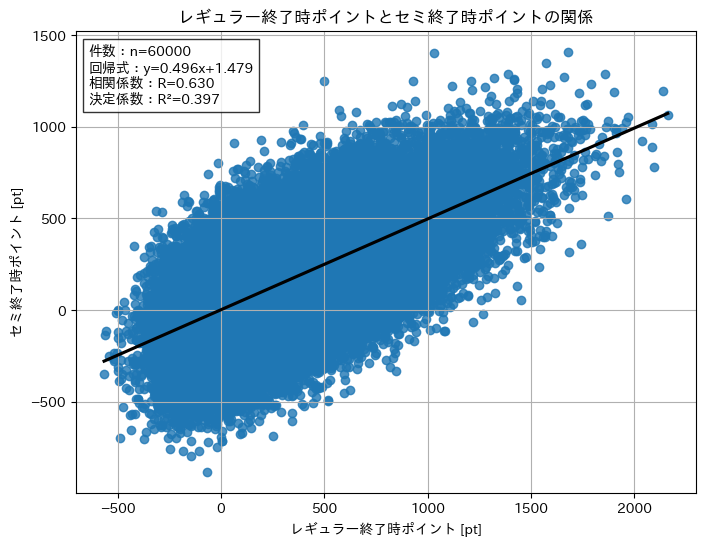

In [9]:
reg_to_semi_n, reg_to_semi_formula, reg_to_semi_corr, reg_to_semi_r2 = plot_point_correlation(
    "regular_end_points",
    "semifinal_end_points",
    "レギュラー",
    "セミ"
)

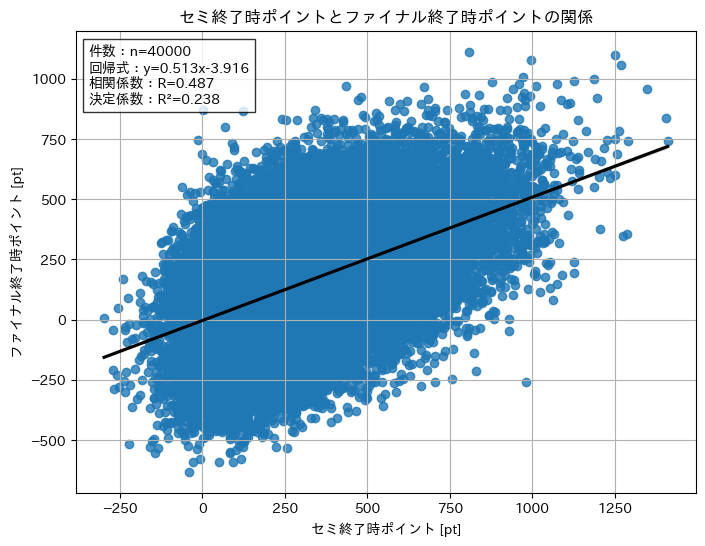

In [10]:
semi_to_final_n, semi_to_final_formula, semi_to_final_corr, semi_to_final_r2 = plot_point_correlation(
    "semifinal_end_points",
    "final_end_points",
    "セミ",
    "ファイナル"
)

In [11]:
diff_corr_r2 = [
    ["レギュラー→セミ",
     reg_to_semi_n,
     reg_to_semi_formula,
     reg_to_semi_corr,
     reg_to_semi_r2
    ],
    ["セミ→ファイナル",
     semi_to_final_n,
     semi_to_final_formula,
     semi_to_final_corr,
     semi_to_final_r2
    ]
]

phase_point_table = pd.DataFrame(
    diff_corr_r2,
    columns=[
        "分析",
        "件数",
        "回帰式",
        "相関係数 R",
        "決定係数 R²"
    ]
)
display(phase_point_table)

,分析,件数,回帰式,相関係数 R,決定係数 R²
0,レギュラー→セミ,60000,y=0.496x+1.479,0.630,0.397
1,セミ→ファイナル,40000,y=0.513x-3.916,0.487,0.238


In [13]:
def plot_rank_correlation(x_col, y_col):
    # 分析対象データの作成
    df_plot = df[[x_col, y_col]].dropna()

    # 件数取得
    n = len(df_plot)

    # スピアマンの順位相関係数
    corr = df_plot[[x_col, y_col]].corr(method="spearman").iloc[0, 1]

    return n, round(corr, 3)

In [14]:
reg_to_semi_rank_n, reg_to_semi_rank_corr = plot_rank_correlation(
    "regular_end_rank",
    "semifinal_end_rank"
)

semi_to_final_rank_n, semi_to_final_rank_corr = plot_rank_correlation(
    "semifinal_end_rank",
    "final_end_rank"
)

diff_corr_rank = [
    ["レギュラー→セミ",
     reg_to_semi_rank_n,
     reg_to_semi_rank_corr
    ],
    ["セミ→ファイナル",
     semi_to_final_rank_n,
     semi_to_final_rank_corr
    ]
]

phase_rank_table = pd.DataFrame(
    diff_corr_rank,
    columns=[
        "分析",
        "件数",
        "順位相関係数 ρ"
    ]
)
display(phase_rank_table)

,分析,件数,順位相関係数 ρ
0,レギュラー→セミ,60000,0.508
1,セミ→ファイナル,40000,0.353


In [15]:
diff_point_rank_corr = [
    ["レギュラー→セミ",
     reg_to_semi_corr,
     reg_to_semi_rank_corr
    ],
    ["セミ→ファイナル",
     semi_to_final_corr,
     semi_to_final_rank_corr
    ]
]

pd.DataFrame(
    diff_point_rank_corr,
    columns=[
        "分析",
        "ポイント相関 R",
        "順位相関 ρ"
    ]
)

,分析,ポイント相関 R,順位相関 ρ
0,レギュラー→セミ,0.630,0.508
1,セミ→ファイナル,0.487,0.353


In [16]:
summary_table = pd.merge(
    phase_point_table,
    phase_rank_table[["分析", "順位相関係数 ρ"]],
    on="分析"
)

display(summary_table)

,分析,件数,回帰式,相関係数 R,決定係数 R²,順位相関係数 ρ
0,レギュラー→セミ,60000,y=0.496x+1.479,0.630,0.397,0.508
1,セミ→ファイナル,40000,y=0.513x-3.916,0.487,0.238,0.353
